In [ ]:
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles.csv


In [ ]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

missing_report.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Percentage (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert date_added to datetime format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].str.strip(),
    errors="coerce"
)

# Remove unnecessary spaces from text columns
text_columns = df_clean.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

Original Dataset: (8807, 12)
Cleaned Dataset: (8807, 12)


In [ ]:
df_clean.info()

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   object        
 2   title         8807 non-null   object        
 3   director      6173 non-null   object        
 4   cast          7982 non-null   object        
 5   country       7976 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8803 non-null   object        
 9   duration      8804 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 825.8+ KB

Remaining Missing Values:
show_id            0
type               0
title              0
director        2634
cast      

In [ ]:
print("Total Netflix Content:", len(df_clean))

print("\nContent Types:")
print(df_clean["type"].value_counts())

print("\nRelease Year Range:")
print(
    df_clean["release_year"].min(),
    "-",
    df_clean["release_year"].max()
)

print("\nTop 10 Countries:")
print(df_clean["country"].value_counts().head(10))

Total Netflix Content: 8807

Content Types:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Release Year Range:
1925 - 2021

Top 10 Countries:
country
United States     2818
India              972
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Set figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("Visualization libraries ready!")

Visualization libraries ready!


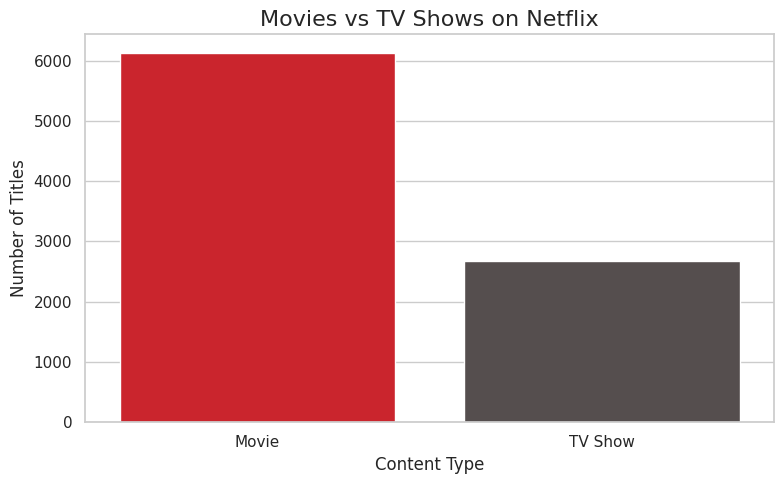

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="type",
    hue="type",
    order=["Movie", "TV Show"],
    palette=["#E50914", "#564D4D"],
    legend=False
)

plt.title("Movies vs TV Shows on Netflix", fontsize=16)
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.savefig("content_by_type.png", dpi=300)
plt.show()

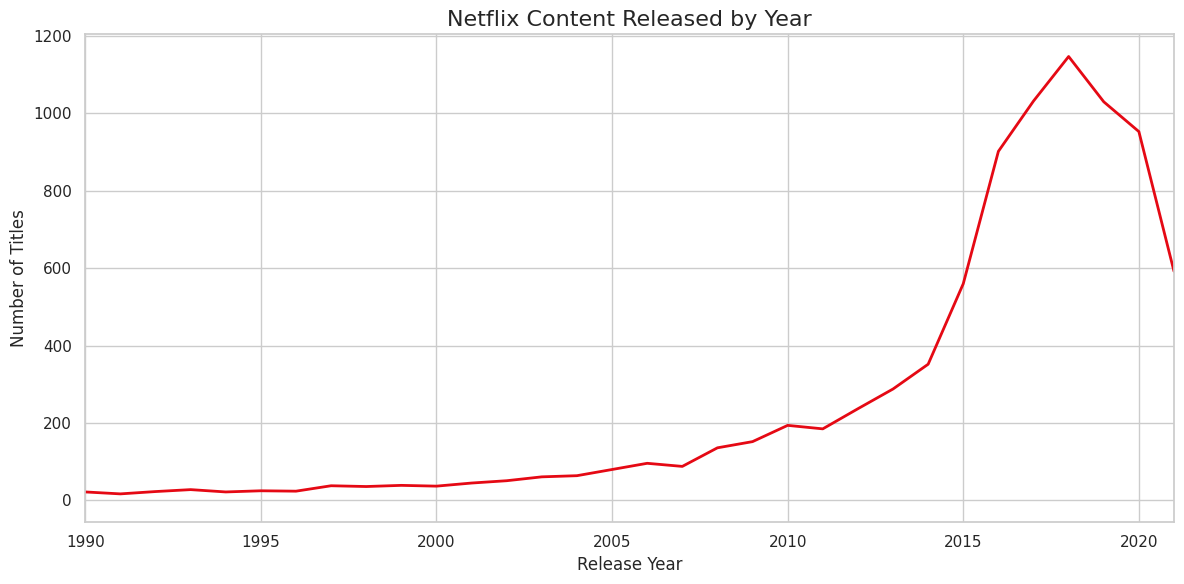

In [ ]:
yearly_content = (
    df_clean["release_year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_content.index,
    yearly_content.values,
    color="#E50914",
    linewidth=2
)

plt.title("Netflix Content Released by Year", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.xlim(1990, yearly_content.index.max())
plt.tight_layout()
plt.savefig("content_by_year.png", dpi=300)
plt.show()

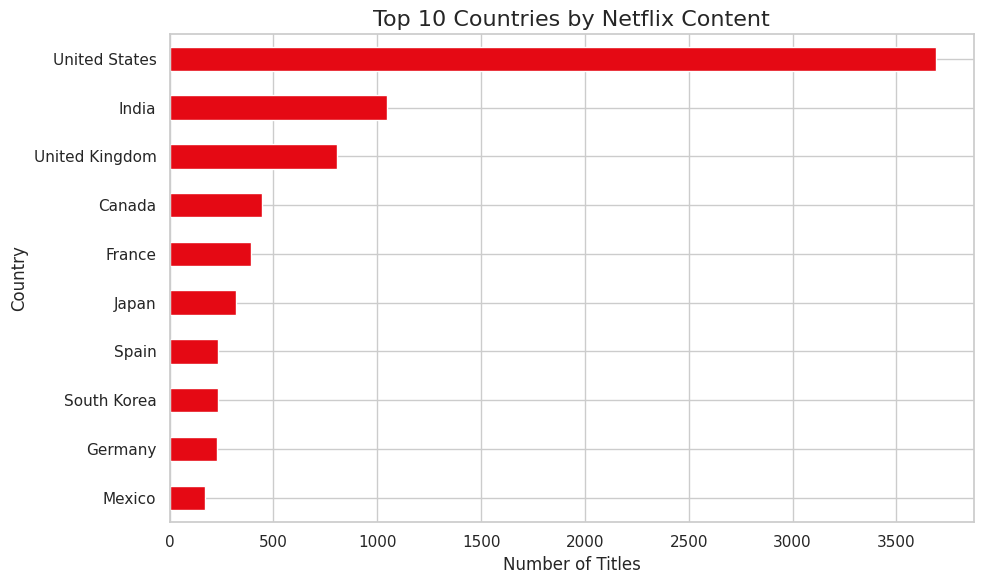

In [ ]:
country_data = (
    df_clean["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

country_data.plot(
    kind="barh",
    color="#E50914"
)

plt.title("Top 10 Countries by Netflix Content", fontsize=16)
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig("top_countries.png", dpi=300)
plt.show()

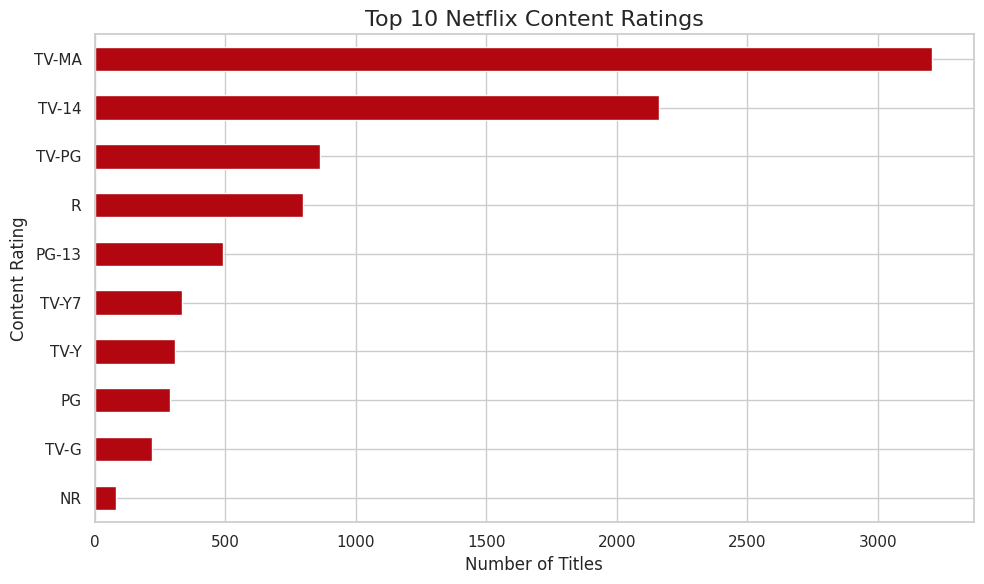

In [ ]:
rating_data = (
    df_clean["rating"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

rating_data.plot(
    kind="barh",
    color="#B20710"
)

plt.title("Top 10 Netflix Content Ratings", fontsize=16)
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")

plt.tight_layout()
plt.savefig("ratings_distribution.png", dpi=300)
plt.show()

In [ ]:
import os

os.makedirs("visualizations", exist_ok=True)

visualization_files = [
    "content_by_type.png",
    "content_by_year.png",
    "top_countries.png",
    "ratings_distribution.png"
]

for file in visualization_files:
    if os.path.exists(file):
        os.replace(
            file,
            f"visualizations/{file}"
        )

print("All visualizations saved successfully!")

All visualizations saved successfully!


In [ ]:
!ls -lh visualizations/

total 468K
-rw-r--r-- 1 root root  88K Nov  5 15:36 content_by_type.png
-rw-r--r-- 1 root root 151K Nov  5 15:36 content_by_year.png
-rw-r--r-- 1 root root  99K Nov  5 15:36 ratings_distribution.png
-rw-r--r-- 1 root root 125K Nov  5 15:36 top_countries.png


In [ ]:
!pip install plotly -q

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

print("Plotly is ready!")

Plotly is ready!


In [ ]:
# Prepare data 1: Content type
type_data = df_clean["type"].value_counts()

# Prepare data 2: Content released by year and type
year_data = (
    df_clean[df_clean["release_year"] >= 1990]
    .groupby(["release_year", "type"])
    .size()
    .reset_index(name="total")
)

# Prepare data 3: Top 10 countries
country_data = (
    df_clean["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
    .sort_values()
)

# Prepare data 4: Ratings
rating_data = (
    df_clean["rating"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

# Create dashboard layout
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Movies vs TV Shows",
        "Content Released by Year",
        "Top 10 Countries",
        "Top 10 Content Ratings"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

# Chart 1: Content Type
fig.add_trace(
    go.Bar(
        x=type_data.index,
        y=type_data.values,
        marker_color=["#E50914", "#777777"],
        name="Content Type"
    ),
    row=1, col=1
)

# Chart 2: Yearly Content
for content_type in ["Movie", "TV Show"]:

    temp = year_data[
        year_data["type"] == content_type
    ]

    fig.add_trace(
        go.Scatter(
            x=temp["release_year"],
            y=temp["total"],
            mode="lines",
            name=content_type
        ),
        row=1, col=2
    )

# Chart 3: Countries
fig.add_trace(
    go.Bar(
        x=country_data.values,
        y=country_data.index,
        orientation="h",
        marker_color="#E50914",
        name="Countries"
    ),
    row=2, col=1
)

# Chart 4: Ratings
fig.add_trace(
    go.Bar(
        x=rating_data.values,
        y=rating_data.index,
        orientation="h",
        marker_color="#B20710",
        name="Ratings"
    ),
    row=2, col=2
)

# Dashboard styling
fig.update_layout(
    title={
        "text": "NETFLIX DATA ANALYTICS DASHBOARD",
        "x": 0.5,
        "xanchor": "center"
    },
    height=850,
    template="plotly_dark",
    showlegend=True,
    barmode="group"
)

fig.show()

In [19]:
import os

os.makedirs("visualizations", exist_ok=True)

fig.write_html(
    "visualizations/netflix_dashboard.html",
    include_plotlyjs=True
)

print("Interactive dashboard saved successfully!")

Interactive dashboard saved successfully!


In [20]:
from google.colab import files

files.download(
    "visualizations/netflix_dashboard.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# 1. Content Type
content_counts = df_clean["type"].value_counts()

total_movies = content_counts.get("Movie", 0)
total_tv_shows = content_counts.get("TV Show", 0)

# 2. Release Year
year_counts = df_clean["release_year"].value_counts()

top_release_year = year_counts.idxmax()
top_release_count = year_counts.max()

# 3. Countries
country_counts = (
    df_clean["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

top_country = country_counts.index[0]
top_country_count = country_counts.iloc[0]

# 4. Ratings
rating_counts = df_clean["rating"].value_counts()

top_rating = rating_counts.index[0]
top_rating_count = rating_counts.iloc[0]

# 5. Genres
genre_counts = (
    df_clean["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

top_genre = genre_counts.index[0]
top_genre_count = genre_counts.iloc[0]

print("NETFLIX DATA INSIGHTS")
print("=" * 40)

print(f"Total Movies: {total_movies:,}")
print(f"Total TV Shows: {total_tv_shows:,}")
print(f"Top Release Year: {top_release_year}")
print(f"Top Country: {top_country}")
print(f"Top Rating: {top_rating}")
print(f"Top Genre: {top_genre}")

NETFLIX DATA INSIGHTS
Total Movies: 6,131
Total TV Shows: 2,676
Top Release Year: 2018
Top Country: United States
Top Rating: TV-MA
Top Genre: International Movies


In [22]:
total_content = len(df_clean)

movie_percentage = (
    total_movies / total_content
) * 100

tv_percentage = (
    total_tv_shows / total_content
) * 100

print(f"Movies: {movie_percentage:.2f}%")
print(f"TV Shows: {tv_percentage:.2f}%")

Movies: 69.62%
TV Shows: 30.38%


In [23]:
insights = f"""
# Netflix Data Analysis Insights

## 1. Content Distribution
Netflix dataset contains {total_content:,} titles.

- Movies: {total_movies:,} ({movie_percentage:.2f}%)
- TV Shows: {total_tv_shows:,} ({tv_percentage:.2f}%)

## 2. Release Year
The year with the highest number of released titles
in this dataset is {top_release_year},
with {top_release_count:,} titles.

## 3. Country Distribution
{top_country} has the highest number of country-title
associations, with {top_country_count:,} records.

Note: Titles associated with multiple countries
are counted for each country.

## 4. Content Ratings
The most common content rating is {top_rating},
with {top_rating_count:,} titles.

## 5. Genre Distribution
The most common genre is {top_genre},
appearing in {top_genre_count:,} titles.

Note: Titles associated with multiple genres
are counted in each genre category.

## Conclusion
The analysis provides an overview of Netflix content
distribution, release years, country associations,
audience ratings, and genre categories.
"""

print(insights)


# Netflix Data Analysis Insights

## 1. Content Distribution
Netflix dataset contains 8,807 titles.

- Movies: 6,131 (69.62%)
- TV Shows: 2,676 (30.38%)

## 2. Release Year
The year with the highest number of released titles
in this dataset is 2018,
with 1,147 titles.

## 3. Country Distribution
United States has the highest number of country-title
associations, with 3,689 records.

Note: Titles associated with multiple countries
are counted for each country.

## 4. Content Ratings
The most common content rating is TV-MA,
with 3,207 titles.

## 5. Genre Distribution
The most common genre is International Movies,
appearing in 2,752 titles.

Note: Titles associated with multiple genres
are counted in each genre category.

## Conclusion
The analysis provides an overview of Netflix content
distribution, release years, country associations,
audience ratings, and genre categories.



In [24]:
import os

os.makedirs("insights", exist_ok=True)

with open(
    "insights/analysis_summary.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(insights)

print("Analysis summary saved successfully!")

Analysis summary saved successfully!


In [25]:
import os

required_files = [
    "visualizations/content_by_type.png",
    "visualizations/content_by_year.png",
    "visualizations/top_countries.png",
    "visualizations/ratings_distribution.png",
    "visualizations/netflix_dashboard.html",
    "insights/analysis_summary.md"
]

print("PROJECT FILE CHECK")
print("=" * 40)

for file in required_files:
    status = "OK" if os.path.exists(file) else "MISSING"
    print(f"{status}: {file}")

PROJECT FILE CHECK
OK: visualizations/content_by_type.png
OK: visualizations/content_by_year.png
OK: visualizations/top_countries.png
OK: visualizations/ratings_distribution.png
OK: visualizations/netflix_dashboard.html
OK: insights/analysis_summary.md


In [35]:
%%writefile README.md

# Netflix Data Visualization & Analysis

## Project Overview

This project explores Netflix Movies and TV Shows data to understand content distribution, release trends, country contributions, and audience ratings.

Using Python and data visualization libraries, this project transforms raw Netflix data into meaningful insights through exploratory data analysis and interactive visualizations.

## Project Objectives

- Explore Netflix Movies and TV Shows data.
- Perform data cleaning and preprocessing.
- Analyze content distribution and release trends.
- Identify top content-producing countries and popular genres.
- Create static and interactive data visualizations.
- Present findings through a structured analysis report.

## Tools & Technologies

- **Python** – Data analysis and processing
- **Pandas** – Data cleaning and manipulation
- **Matplotlib** – Static data visualization
- **Seaborn** – Statistical data visualization
- **Plotly** – Interactive dashboard
- **Google Colab** – Development environment

## Dataset

The dataset contains information about Netflix movies and TV shows, including:

- Content type and title
- Director and cast
- Country of production
- Date added to Netflix
- Release year
- Content rating
- Duration
- Genre categories
- Content descriptions

**Source:** [Netflix Movies and TV Shows Dataset – Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows)

## Data Analysis Process

1. Data Collection – Import the Netflix dataset.
2. Data Cleaning – Handle missing values, duplicates, and date formatting.
3. Exploratory Data Analysis – Examine content distribution and dataset characteristics.
4. Data Visualization – Create charts to identify patterns and trends.
5. Insight Generation – Summarize findings from the analysis.

## Visualizations

### 1. Movies vs TV Shows

![Content Type](visualizations/content_by_type.png)

### 2. Netflix Content Released by Year

![Content by Year](visualizations/content_by_year.png)

### 3. Top 10 Countries

![Top Countries](visualizations/top_countries.png)

### 4. Content Ratings Distribution

![Content Ratings](visualizations/ratings_distribution.png)

## Interactive Dashboard

An interactive dashboard was developed using Plotly to explore Netflix content distribution, release trends, countries, and ratings.

**Dashboard file:** `visualizations/netflix_dashboard.html`

## Key Insights

See [Analysis Summary](insights/analysis_summary.md) for the findings generated from the dataset.

## Project Structure

```text
netflix-data-visualization/
│
├── README.md
├── data/
│   └── netflix_titles.csv
├── notebooks/
│   └── netflix_analysis.ipynb
├── visualizations/
│   ├── content_by_type.png
│   ├── content_by_year.png
│   ├── top_countries.png
│   ├── ratings_distribution.png
│   └── netflix_dashboard.html
└── insights/
    └── analysis_summary.md
```

## How to Run

1. Clone this repository.
2. Open the notebook in Google Colab.
3. Upload the Netflix dataset if it is not included.
4. Run the notebook cells sequentially.
5. Explore the generated visualizations and analysis results.

## Author

**Data Analytics Portfolio Project**

This project was developed for learning and portfolio purposes.

Overwriting README.md


In [36]:
import os
import shutil

# Create project folders
folders = [
    "data",
    "notebooks",
    "visualizations",
    "insights"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Copy dataset
if os.path.exists("netflix_titles.csv"):
    shutil.copy(
        "netflix_titles.csv",
        "data/netflix_titles.csv"
    )

print("Project folders created successfully!")

Project folders created successfully!


In [37]:
!find . -maxdepth 2 -type f | sort

./.config/active_config
./.config/config_sentinel
./.config/default_configs.db
./.config/gce
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/.last_opt_in_prompt.yaml
./.config/.last_survey_prompt.yaml
./.config/.last_update_check.json
./data/netflix_titles.csv
./insights/analysis_summary.md
./netflix_titles.csv
./README.md
./sample_data/anscombe.json
./sample_data/california_housing_test.csv
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/README.md
./visualizations/content_by_type.png
./visualizations/content_by_year.png
./visualizations/netflix_dashboard.html
./visualizations/ratings_distribution.png
./visualizations/top_countries.png
